In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

from graphviz import Source
from IPython.display import display

In [61]:
COLS = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income",
]

DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
TEST_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test"


def load_adult(path_or_url):
    first = pd.read_csv(
        path_or_url,
        nrows=1,
        header=None,
        comment="|",
        skipinitialspace=True,
    ).iloc[0, 0]

    header = 0 if str(first).strip().lower() == "age" else None
    names = None if header == 0 else COLS

    df = pd.read_csv(
        path_or_url,
        header=header,
        names=names,
        na_values=["?"],
        skipinitialspace=True,
        comment="|",
    )

    if df.shape[1] == len(COLS):
        df.columns = COLS

    df["income"] = df["income"].astype(str).str.strip().str.rstrip(".")
    df = df[df["income"].isin(["<=50K", ">50K"])]
    df["income"] = (df["income"] == ">50K").astype(int)

    return df


train_raw = load_adult(DATA_URL)
test_raw = load_adult(TEST_URL)

df_all = pd.concat([train_raw, test_raw], ignore_index=True)

print("Размер данных:", df_all.shape)
print("Распределение дохода:\n", df_all["income"].value_counts(normalize=True))
df_all.head()

Размер данных: (48842, 15)
Распределение дохода:
 income
0    0.760718
1    0.239282
Name: proportion, dtype: float64


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


In [62]:
NUM_COLS = [
    "age",
    "fnlwgt",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
]

CAT_COLS = [c for c in COLS if c not in NUM_COLS + ["income"]]


def preprocess(train_df, test_df=None):
    X_train = train_df.drop(columns="income").copy()
    y_train = train_df["income"].values

    medians = {c: X_train[c].median() for c in NUM_COLS}

    X_train[NUM_COLS] = X_train[NUM_COLS].fillna(medians)
    X_train[CAT_COLS] = X_train[CAT_COLS].fillna("Unknown")
    X_train = pd.get_dummies(X_train, columns=CAT_COLS)

    if test_df is None:
        return X_train.values.astype(float), y_train, None, None, list(X_train.columns)

    X_test = test_df.drop(columns="income").copy()
    y_test = test_df["income"].values

    X_test[NUM_COLS] = X_test[NUM_COLS].fillna(medians)
    X_test[CAT_COLS] = X_test[CAT_COLS].fillna("Unknown")
    X_test = pd.get_dummies(X_test, columns=CAT_COLS)

    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

    return (
        X_train.values.astype(float),
        y_train,
        X_test.values.astype(float),
        y_test,
        list(X_train.columns),
    )

In [63]:
def entropy_p(p):
    if p <= 0 or p >= 1:
        return 0.0
    return -p * np.log2(p) - (1 - p) * np.log2(1 - p)


class SimpleDecisionTree:
    def __init__(
        self,
        criterion="info_gain",
        max_depth=4,
        min_samples_split=50,
        min_samples_leaf=20,
        max_bins=10,
    ):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.max_bins = max_bins

    def fit(self, X, y):
        self.thresholds_ = [self._make_thresholds(X[:, j]) for j in range(X.shape[1])]
        self.root_ = self._build(X, y, depth=0)
        return self

    def _make_thresholds(self, col):
      uniq, counts = np.unique(col, return_counts=True)

      if len(uniq) <= 1:
          return np.array([])
      if len(uniq) <= self.max_bins + 1:
          return (uniq[:-1] + uniq[1:]) / 2.0\

      cum = np.concatenate([[0], np.cumsum(counts)])
      targets = np.linspace(0, len(col), self.max_bins * 3 + 1)[1:-1]
      idx = np.unique(np.clip(np.searchsorted(cum, targets, side="right") - 1, 0, len(uniq) - 2))

      return (uniq[idx] + uniq[idx + 1]) / 2.0

    def _impurity(self, y):
        if len(y) == 0:
            return 0.0

        p = y.mean()

        if self.criterion == "gini":
            return 2 * p * (1 - p)

        return entropy_p(p)

    def _best_split(self, X, y):
        n = len(y)
        parent_impurity = self._impurity(y)

        best_score = -1.0
        best_split = None

        for feature_idx, thresholds in enumerate(self.thresholds_):
            for threshold in thresholds:
                left_mask = X[:, feature_idx] <= threshold
                right_mask = ~left_mask

                n_left = left_mask.sum()
                n_right = n - n_left

                if n_left < self.min_samples_leaf or n_right < self.min_samples_leaf:
                    continue

                y_left = y[left_mask]
                y_right = y[right_mask]

                child_impurity = (
                    n_left * self._impurity(y_left)
                    + n_right * self._impurity(y_right)
                ) / n

                gain = parent_impurity - child_impurity

                if gain <= 1e-8:
                    continue

                if self.criterion == "gain_ratio":
                    split_info = entropy_p(n_left / n)
                    if split_info <= 1e-8:
                        continue
                    score = gain / split_info
                else:
                    score = gain

                if score > best_score:
                    best_score = score
                    best_split = (feature_idx, float(threshold), float(gain))

        return best_split

    def _build(self, X, y, depth):
        n0 = int((y == 0).sum())
        n1 = int((y == 1).sum())

        node = {
            "samples": len(y),
            "value": [n0, n1],
            "impurity": self._impurity(y),
            "label": int(n1 > n0),
            "feature": None,
            "threshold": None,
            "left": None,
            "right": None,
        }

        stop_by_depth = self.max_depth is not None and depth >= self.max_depth
        stop_by_size = len(y) < self.min_samples_split
        stop_by_purity = node["impurity"] == 0.0

        if stop_by_depth or stop_by_size or stop_by_purity:
            return node

        split = self._best_split(X, y)

        if split is None:
            return node

        feature_idx, threshold, gain = split
        left_mask = X[:, feature_idx] <= threshold
        right_mask = ~left_mask

        if left_mask.sum() < self.min_samples_leaf or right_mask.sum() < self.min_samples_leaf:
            return node

        node["feature"] = feature_idx
        node["threshold"] = threshold
        node["gain"] = gain
        node["left"] = self._build(X[left_mask], y[left_mask], depth + 1)
        node["right"] = self._build(X[right_mask], y[right_mask], depth + 1)

        return node

    def predict(self, X):
        return np.array([self._predict_one(x) for x in X], dtype=int)

    def _predict_one(self, x):
        node = self.root_

        while node["feature"] is not None:
            if x[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]

        return node["label"]

In [64]:
def calc_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }


def tree_to_dot(model, feature_names, max_depth=3):
    lines = [
        "digraph Tree {",
        'node [shape=box, style=filled, fontname="Helvetica"];',
    ]

    counter = [0]

    def add_node(node, depth):
        if depth > max_depth:
            node_id = counter[0]
            counter[0] += 1
            lines.append(f'{node_id} [label="..." fillcolor="white"];')
            return node_id

        node_id = counter[0]
        counter[0] += 1

        if node["feature"] is None:
            label = f"{'>50K' if node['label'] else '<=50K'}\\nsamples={node['samples']}"
            color = "#ff9999" if node["label"] == 1 else "#99ccff"
        else:
            feature_name = feature_names[node["feature"]]
            label = (
                f"{feature_name}\\n"
                f"<= {node['threshold']:.2f}\\n"
                f"samples={node['samples']}"
            )
            color = "#ff9999" if node["label"] == 1 else "#99ccff"

        lines.append(f'{node_id} [label="{label}" fillcolor="{color}"];')

        if node["feature"] is not None:
            left_id = add_node(node["left"], depth + 1)
            right_id = add_node(node["right"], depth + 1)

            lines.append(f'{node_id} -> {left_id} [label="true"];')
            lines.append(f'{node_id} -> {right_id} [label="false"];')

        return node_id

    add_node(model.root_, 0)
    lines.append("}")

    return "\n".join(lines)


def show_tree(model, feature_names, max_depth=3):
    dot_code = tree_to_dot(model, feature_names, max_depth=max_depth)
    return Source(dot_code)

In [65]:
def run_tree(
    criterion="info_gain",
    train_size=0.8,
    max_depth=4,
    random_state=42,
    show=True,
):
    if train_size >= 1.0:
        train_df = df_all
        test_df = None
    else:
        train_df, test_df = train_test_split(
            df_all,
            train_size=train_size,
            stratify=df_all["income"],
            random_state=random_state,
        )

    X_train, y_train, X_test, y_test, feature_names = preprocess(train_df, test_df)

    model = SimpleDecisionTree(
        criterion=criterion,
        max_depth=max_depth,
    ).fit(X_train, y_train)

    result = None

    if X_test is not None:
        y_pred = model.predict(X_test)
        result = calc_metrics(y_test, y_pred)
        print(pd.Series(result))

    if show:
        display(show_tree(model, feature_names, max_depth=min(3, max_depth)))

    return model, feature_names, result

Критерий: info_gain


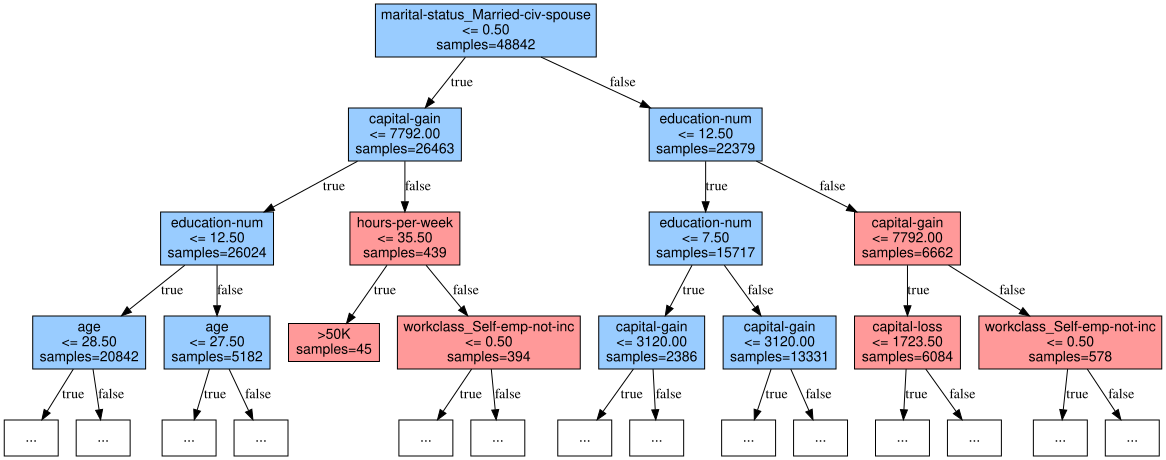

Критерий: gain_ratio


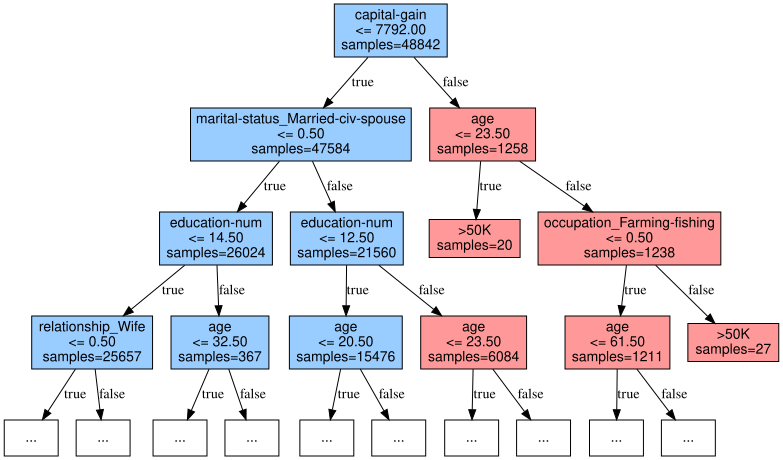

Критерий: gini


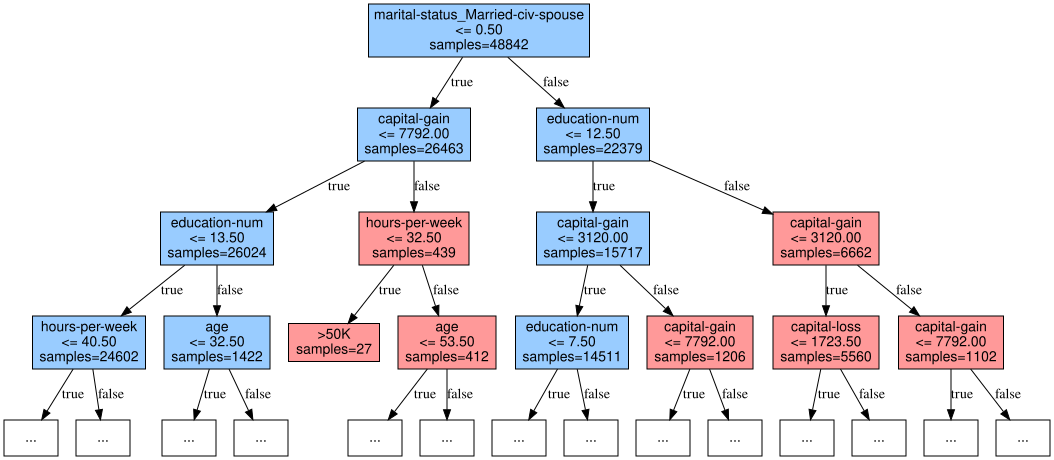

In [66]:
for criterion in ["info_gain", "gain_ratio", "gini"]:
    print(f"Критерий: {criterion}")
    run_tree(criterion=criterion, train_size=1.0, max_depth=4, show=True)

In [69]:
def run_experiment(
    criteria=("info_gain", "gain_ratio", "gini"),
    ratios=(0.6, 0.7, 0.8, 0.9),
    max_depth=4,
    random_state=42,
):
    rows = []

    for ratio in ratios:
        train_df, test_df = train_test_split(
            df_all,
            train_size=ratio,
            stratify=df_all["income"],
            random_state=random_state,
        )

        X_train, y_train, X_test, y_test, feature_names = preprocess(train_df, test_df)

        for criterion in criteria:
            model = SimpleDecisionTree(
                criterion=criterion,
                max_depth=max_depth,
            ).fit(X_train, y_train)

            y_pred = model.predict(X_test)
            metrics = calc_metrics(y_test, y_pred)

            row = {
                "criterion": criterion,
                "train_size": ratio,
                **metrics,
            }

            rows.append(row)

    results = pd.DataFrame(rows)

    display(results)

    metrics_to_plot = ["accuracy", "precision", "recall", "f1"]

    for metric in metrics_to_plot:
        plt.figure(figsize=(6, 4))

        for crit, group in results.groupby("criterion"):
            group = group.sort_values("train_size")
            plt.plot(
                group["train_size"],
                group[metric],
                marker="o",
                label=crit,
            )

        plt.title(f"{metric} vs train size")
        plt.xlabel("Доля обучающей выборки")
        plt.ylabel(metric)

        plt.xticks(
            list(ratios),
            [f"{int(r * 100)}%" for r in ratios],
        )

        plt.grid(alpha=0.3)
        plt.legend()
        plt.show()

    return results

,criterion,train_size,accuracy,precision,recall,f1
0,info_gain,0.6,0.844551,0.766602,0.503743,0.607977
1,gain_ratio,0.6,0.846957,0.740234,0.555294,0.634564
2,gini,0.6,0.849004,0.766780,0.530267,0.626960
3,info_gain,0.7,0.844537,0.728423,0.558471,0.632225
4,gain_ratio,0.7,0.845219,0.733938,0.553908,0.631339
5,gini,0.7,0.846448,0.740245,0.551911,0.632353
6,info_gain,0.8,0.847477,0.757908,0.532934,0.625816
7,gain_ratio,0.8,0.844201,0.728443,0.556459,0.630941
8,gini,0.8,0.848398,0.758600,0.537639,0.629287
9,info_gain,0.9,0.847492,0.752381,0.540633,0.629169


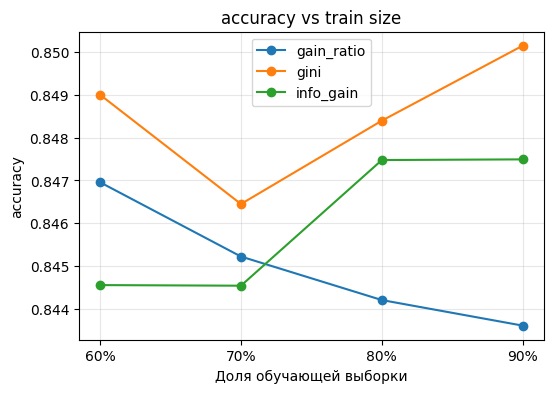

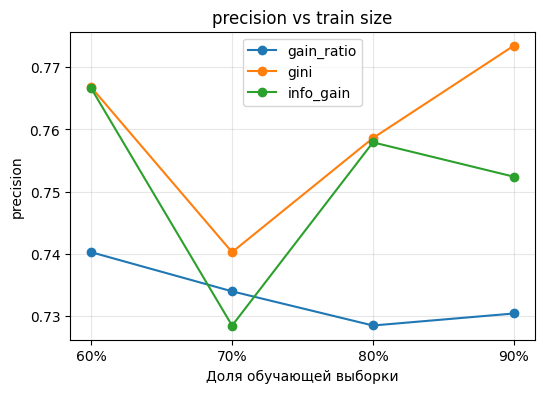

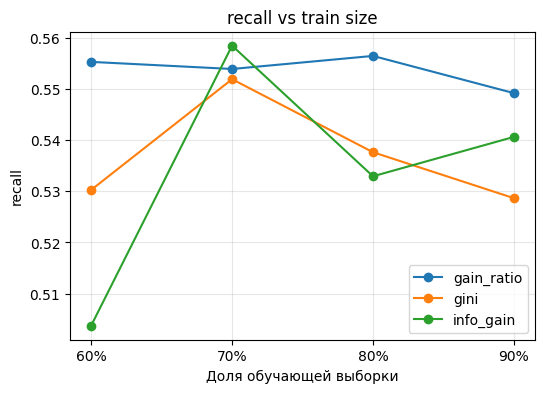

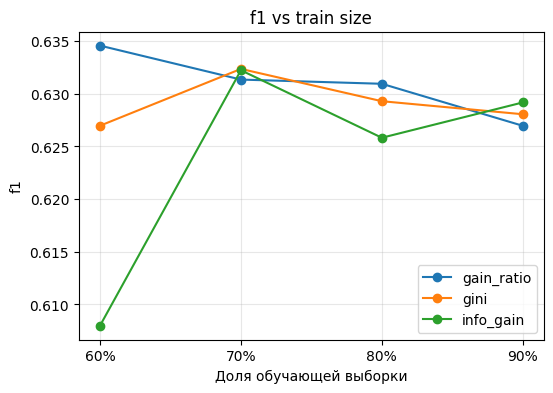

In [72]:
results = run_experiment(
    criteria=("info_gain", "gain_ratio", "gini"),
    ratios=(0.6, 0.7, 0.8, 0.9),
    max_depth=6,
    random_state=42,
)